# Traffic and Clients
Input: `data/logs.parquet` from `01_load_clean.ipynb`.

In [1]:
import pandas as pd
import plotly.express as px
import plotly.io as pio
pio.renderers.default = 'plotly_mimetype+png'  # PNG copy so charts show on GitHub

In [2]:
df = pd.read_parquet('data/logs.parquet')
len(df)

1187827

## 1. Status breakdown

In [3]:
df['status_class'] = (df.status_code // 100).astype(str) + 'xx'
df.status_class.value_counts()


status_class
2xx    717144
4xx    416615
3xx     27328
5xx     19891
1xx      6849
Name: count, dtype: int64

In [4]:
status = pd.crosstab([df.domain, df.subdomain], df.status_class)
status.sort_values('5xx', ascending=False).head(10)

status_class                1xx    2xx   3xx   4xx    5xx
domain       subdomain                                   
humblebee.ai speakology       0      0     0    14  11874
             outline       2433  21642  1468   218   2474
             customs-ocr      0  24005     0    15   1375
             chatbot          0  22322     2    30    784
             jnj              9  80904    12   284    713
             smart-office     0      0     0     0    630
hbai.dev     outline       1564  37555   260  5546    487
             secrets         43  69715  8913  4680    323
humblebee.ai repo-holmes      0      0     0     1    284
hbai.dev     langfuse         0  34639    24  2011    225

In [5]:
status_pct = pd.crosstab([df.domain, df.subdomain], df.status_class, normalize='index').round(3)
status_pct['total'] = df.groupby(['domain', 'subdomain']).size()
status_pct[status_pct.total>=100].sort_values('5xx', ascending=False)


status_class                   1xx    2xx    3xx    4xx    5xx   total
domain       subdomain                                                
humblebee.ai smart-office    0.000  0.000  0.000  0.000  1.000     630
             speakology      0.000  0.000  0.000  0.001  0.999   11888
             repo-holmes     0.000  0.000  0.000  0.004  0.996     285
             outline         0.086  0.766  0.052  0.008  0.088   28235
             customs-ocr     0.000  0.945  0.000  0.001  0.054   25395
             chatbot         0.000  0.965  0.000  0.001  0.034   23138
hbai.dev     outline         0.034  0.827  0.006  0.122  0.011   45412
humblebee.ai jnj             0.000  0.988  0.000  0.003  0.009   81922
hbai.dev     langfuse        0.000  0.939  0.001  0.055  0.006   36899
             dns             0.000  0.348  0.251  0.396  0.006    3704
             servers         0.010  0.093  0.000  0.892  0.005   23087
             uptime          0.016  0.497  0.449  0.033  0.005    3115
             secrets         0.001  0.833  0.107  0.056  0.004   83674
humblebee.ai hstaff          0.000  0.811  0.004  0.182  0.003   61792
hbai.dev     it-tools        0.000  0.997  0.002  0.000  0.002    8592
             homepage        0.000  0.874  0.109  0.015  0.002   66742
humblebee.ai access          0.000  0.982  0.009  0.008  0.001   35917
             humblebee.ai    0.000  0.582  0.086  0.330  0.001   58752
hbai.dev     pass            0.079  0.847  0.003  0.070  0.001   31722
humblebee.ai roadmap         0.000  0.413  0.583  0.004  0.000     980
             qalb-api        0.000  0.999  0.000  0.000  0.000   11549
             shomila         0.000  0.927  0.073  0.000  0.000     165
             infer           0.000  0.994  0.000  0.006  0.000   25816
             status          0.000  0.971  0.008  0.021  0.000    3323
             test            0.000  0.043  0.003  0.954  0.000     325
             tex             0.000  0.993  0.001  0.005  0.000   13413
             similar-search  0.000  0.999  0.000  0.000  0.000   11560
             biomarker       0.000  0.999  0.000  0.000  0.000   11546
             dex             0.000  0.918  0.000  0.081  0.000   38036
             bride           0.000  0.899  0.000  0.101  0.000    7251
             attendance      0.000  0.523  0.004  0.472  0.000    8375
             api-hstaff      0.000  0.905  0.000  0.095  0.000   58210
             a-honeypot      0.000  0.000  0.000  1.000  0.000  328713
hbai.dev     test            0.000  0.987  0.013  0.000  0.000     539
             status          0.000  0.422  0.465  0.113  0.000    1044
             plane           0.000  0.206  0.013  0.782  0.000    5659
             mail            0.000  1.000  0.000  0.000  0.000    8639
             kr-router-2     0.000  0.887  0.113  0.000  0.000     619
             kr-router-1     0.000  1.000  0.000  0.000  0.000     719
             hubstaff        0.000  0.962  0.000  0.038  0.000    8604
humblebee.ai video-gen       0.000  1.000  0.000  0.000  0.000   11545

## 2. Traffic over time

In [6]:
ts = df.set_index('datetime').sort_index()
daily = ts.resample('1D').size() # separate bty 1 day
daily # find how many requets per day

datetime
2026-10-21 00:00:00+09:00     47149
2026-10-22 00:00:00+09:00    195268
2026-10-23 00:00:00+09:00     96366
2026-10-24 00:00:00+09:00    100573
2026-10-25 00:00:00+09:00     95760
2026-10-26 00:00:00+09:00    161040
2026-10-27 00:00:00+09:00    244646
2026-10-28 00:00:00+09:00    182532
2026-10-29 00:00:00+09:00     64493
Freq: D, dtype: int64

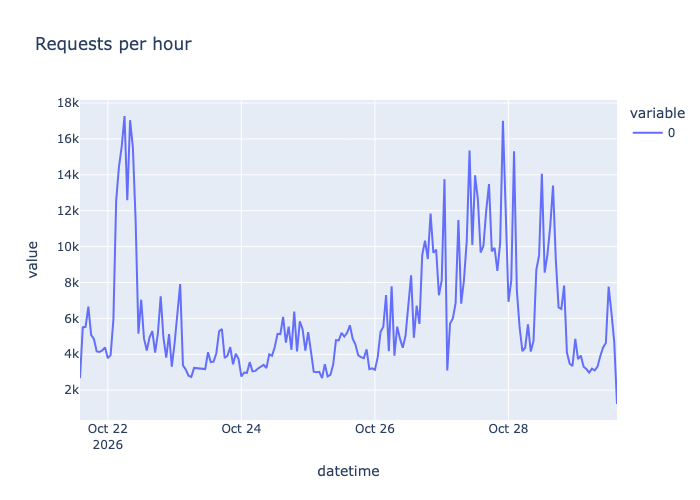

In [7]:
hourly = ts.resample('1h').size() # separate by hour 1
px.line(hourly, title="Requests per hour")


In [8]:
real = ts[ts.subdomain != 'a-honeypot']
pd.DataFrame({'all': daily, 'no_honeypot': real.resample('1D').size()})

,all,no_honeypot
datetime,,
2026-10-21 00:00:00+09:00,47149,40977
2026-10-22 00:00:00+09:00,195268,99459
2026-10-23 00:00:00+09:00,96366,83873
2026-10-24 00:00:00+09:00,100573,89806
2026-10-25 00:00:00+09:00,95760,85215
2026-10-26 00:00:00+09:00,161040,99537
2026-10-27 00:00:00+09:00,244646,157447
2026-10-28 00:00:00+09:00,182532,138684
2026-10-29 00:00:00+09:00,64493,64116


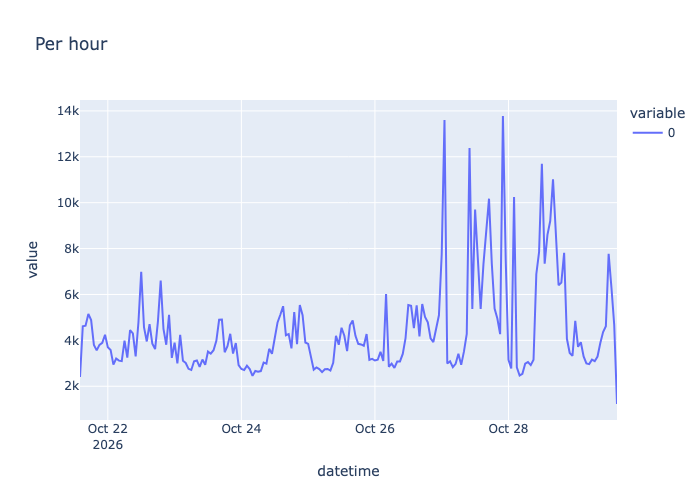

In [9]:
per_hour = real.resample('1h').size() # without honeypot
px.line(per_hour, title="Per hour")

In [10]:
df.datetime.dt.hour.value_counts().sort_index()

datetime
0     39416
1     46995
2     47400
3     44596
4     45632
5     42307
6     53510
7     41371
8     47647
9     49232
10    56169
11    46279
12    63358
13    54450
14    49628
15    55295
16    56719
17    58528
18    48912
19    51973
20    49704
21    45438
22    52239
23    41029
Name: count, dtype: int64

**Traffic findings**
- First and last day are partial (logs 2026-10-21 14:38 to 2026-10-29 15:13).
- Oct 22 06:00 spike: honeypot, 13,294 requests from 11 IPs. Gone without honeypot.
- Oct 27 22:00 spike: real traffic, 7,347 requests from one IP to homepage. Check in step 4.

## 3. Slow endpoints
IDs in URLs are replaced with placeholders so one endpoint is one group. Long-lived connections (status 101, WebSocket) are excluded: they stay open on purpose.

In [11]:
UUID = r'[0-9a-fA-F]{8}-[0-9a-fA-F]{4}-[0-9a-fA-F]{4}-[0-9a-fA-F]{4}-[0-9a-fA-F]{12}'

df['endpoint'] = (df.uri.str.split('?').str[0]
                    .str.replace(UUID, '{id}', regex=True)
                    .str.replace(r'/\d+(?=/|$)', '/{n}', regex=True)) # file in folder
df.uri.nunique(), df.endpoint.nunique()

(39459, 15619)

In [12]:
long_lived = df[df.status_code == 101] # ws
len(long_lived), long_lived.response_time.median()

(6849, 339.506)

In [13]:
fast = df[(df.status_code != 101) & (df.subdomain != 'a-honeypot')]

slow = (fast.groupby(['subdomain', 'endpoint'])
          .response_time.agg(['count', 'median', 'max']) # max the worst, slow
          .query('count >= 20')
          .sort_values('median', ascending=False))
slow.head(15)

count  \
subdomain    endpoint                                                    
servers      /api/collections/users/auth-with-password              22   
api-hstaff   /api/v1/hubstaff/task-time                            406   
langfuse     /api/public/traces                                    295   
bride        /api/v1/auth/hstaff                                    37   
homepage     /api/docker/stats                                     967   
access       /api/v1/onboarding/readiness                           58   
bride        /api/v1/attendance/today                             2486   
             /api/v1/attendance/afk                                 76   
             /api/v1/attendance/auto-check-in                      120   
             /api/v1/attendance/planned-checkout                    20   
             /api/v1/attendance/check-in                            70   
humblebee.ai /images/projects/thumbnails/ai-avatar/ai-avatar...     34   
bride        /api/v1/employees/me                                  475   
             /api/v1/hstaff/inbox                                 1041   
access       /api/v1/auth/login                                     64   

                                                                  median  \
subdomain    endpoint                                                      
servers      /api/collections/users/auth-with-password           15.1045   
api-hstaff   /api/v1/hubstaff/task-time                           3.3105   
langfuse     /api/public/traces                                   2.7520   
bride        /api/v1/auth/hstaff                                  2.6160   
homepage     /api/docker/stats                                    2.4110   
access       /api/v1/onboarding/readiness                         2.3860   
bride        /api/v1/attendance/today                             2.1975   
             /api/v1/attendance/afk                               2.1355   
             /api/v1/attendance/auto-check-in                     2.0355   
             /api/v1/attendance/planned-checkout                  1.8530   
             /api/v1/attendance/check-in                          1.8320   
humblebee.ai /images/projects/thumbnails/ai-avatar/ai-avatar...   1.6195   
bride        /api/v1/employees/me                                 1.5700   
             /api/v1/hstaff/inbox                                 1.2560   
access       /api/v1/auth/login                                   1.2495   

                                                                    max  
subdomain    endpoint                                                    
servers      /api/collections/users/auth-with-password           15.121  
api-hstaff   /api/v1/hubstaff/task-time                          33.512  
langfuse     /api/public/traces                                   5.444  
bride        /api/v1/auth/hstaff                                  3.692  
homepage     /api/docker/stats                                   18.262  
access       /api/v1/onboarding/readiness                         3.583  
bride        /api/v1/attendance/today                             9.972  
             /api/v1/attendance/afk                               4.405  
             /api/v1/attendance/auto-check-in                     2.872  
             /api/v1/attendance/planned-checkout                  4.371  
             /api/v1/attendance/check-in                          2.973  
humblebee.ai /images/projects/thumbnails/ai-avatar/ai-avatar...   3.818  
bride        /api/v1/employees/me                                 5.801  
             /api/v1/hstaff/inbox                                 3.946  
access       /api/v1/auth/login                                   2.381

**Slow endpoint findings**
- `servers` `/api/collections/users/auth-with-password`: 15.1 s median, 15.12 s max. Same time every request. Step 4 shows these are 22 POSTs from internal IPs, 16 succeed: real users, not brute force. Cause of the delay still unknown.
- `api-hstaff` `/api/v1/hubstaff/task-time`: 3.3 s median over 406 requests, one at 33.5 s.

## 4. Top IPs and user agents
Each user agent gets one label. Rules are checked in order, first match wins, so bots that pretend to be browsers (`Mozilla/5.0 ... bingbot`) are caught before the browser rule.

In [14]:
import re

UA_RULES = [
    ('monitoring', r'uptime|pingdom|statuscake|healthcheck|monitor'),
    ('scanner',    r'scan|zgrab|masscan|nmap|nuclei|sqlmap|nikto|censys|fuzz|dirb|gobuster'),
    ('crawler',    r'bot|crawl|spider|slurp|facebookexternalhit|-user'),
    ('ai_agent',   r'claude-code|codex|mcp'),
    ('script',     r'python|httpx|aiohttp|curl|wget|node|axios|okhttp|go-http|java|ruby|dart|otel|^cli/'),
    ('browser',    r'mozilla.*(chrome|firefox|safari|edg)'),
]

def label_ua(ua):
    for label, pattern in UA_RULES:
        if re.search(pattern, ua, re.IGNORECASE):
            return label
    return 'other'

labels = {ua: label_ua(ua) for ua in df.http_user_agent.dropna().unique()}
df['client_type'] = df.http_user_agent.map(labels).fillna('unknown')
len(labels)

1605

In [15]:
real = df[df.subdomain != 'a-honeypot']
pd.DataFrame({'requests': real.client_type.value_counts(),
              'share': real.client_type.value_counts(normalize=True).round(3)})

,requests,share
client_type,,
monitoring,303092,0.353
browser,266115,0.310
script,187593,0.218
ai_agent,66271,0.077
crawler,15935,0.019
unknown,14015,0.016
other,5649,0.007
scanner,444,0.001


In [16]:
pd.crosstab(real.client_type, real.status_class, normalize='index').round(3)

status_class,1xx,2xx,3xx,4xx,5xx
client_type,,,,,
ai_agent,0.000,0.694,0.000,0.302,0.004
browser,0.026,0.694,0.091,0.174,0.016
crawler,0.000,0.652,0.034,0.294,0.020
monitoring,0.000,0.954,0.000,0.000,0.046
other,0.000,0.561,0.027,0.358,0.054
scanner,0.000,0.104,0.268,0.516,0.113
script,0.000,0.925,0.001,0.071,0.003
unknown,0.000,0.737,0.161,0.081,0.021


In [17]:
real[real.client_type == 'other'].http_user_agent.value_counts().head(10)

http_user_agent
Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36                                                                                                733
undici                                                                                                                                                      674
Bun/1.4.4                                                                                                                                                   667
PeecAudit/1.0 (+https://peec.ai)                                                                                                                            299
cli                                                                                                                                                         299
Hermes-Agent/0.22.2                                                                                                                                         205
Mozlila/5.0 (Linux; Andr

### Internal or public IP
`100.64.0.0/10` is the CGNAT range used by Tailscale, so those are our own machines. Python treats it as neither private nor public, so it is checked by hand.

In [18]:
import ipaddress

CGNAT = ipaddress.ip_network('100.64.0.0/10')

def ip_kind(ip):
    try:
        a = ipaddress.ip_address(ip)
    except ValueError:
        return 'invalid'
    return 'internal' if a.is_private or a in CGNAT else 'public'
# tailscale bo'lsa, cgnat; if not private _>public

kinds = {ip: ip_kind(ip) for ip in df.client_address.unique()}
df['ip_kind'] = df.client_address.map(kinds)
real = df[df.subdomain != 'a-honeypot']
real.ip_kind.value_counts()

ip_kind
public      711519
internal    147595
Name: count, dtype: int64

### Top ips table

In [19]:
top_ips = (real.groupby('client_address')
             .agg(requests=('request_id', 'size'),
                  subdomains=('subdomain', 'nunique'),
                  main_type=('client_type', lambda s: s.mode()[0]),
                  share_4xx=('status_class', lambda s: round((s == '4xx').mean(), 3)),
                  ip_kind=('ip_kind', 'first'))
             .sort_values('requests', ascending=False))
top_ips.head(12)

,requests,subdomains,main_type,share_4xx,ip_kind
client_address,,,,,
52.78.14.x,242445,15,monitoring,0.000,public
169.212.33.x,105630,31,monitoring,0.062,public
121.142.158.x,77376,27,script,0.029,public
100.69.50.127,74098,12,browser,0.015,internal
3.6.124.x,53552,2,script,0.080,public
87.192.248.x,37704,15,browser,0.149,public
100.100.217.105,20391,12,unknown,0.008,internal
100.100.1.80,19559,1,browser,1.000,internal
13.235.251.x,14522,1,script,0.005,public


### Check the suspicious ones

In [20]:
# 100% 4xx from one internal IP
x = real[real.client_address == '100.100.1.80']
x.groupby(['subdomain', 'endpoint', 'status_code', 'http_user_agent']).size()

subdomain  endpoint                   status_code  http_user_agent                                                                                                
servers    /api/beszel/agent-connect  401          Mozilla/5.0 (Windows NT 11.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0.0.x Safari/537.36    19554
                                      502          Mozilla/5.0 (Windows NT 11.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0.0.x Safari/537.36        5
dtype: int64

In [21]:
# the Oct 27 22:00 spike
ts = real.set_index('datetime').sort_index()
spike = ts.loc['2026-10-27 22:00':'2026-10-27 22:59'] # high traffic bo'lgan time
spike_ip = spike.client_address.value_counts().index[0]
spike_ip, spike[spike.client_address == spike_ip].endpoint.value_counts().head(5)

('100.69.50.127',
 endpoint
 /api/widgets/resources    4040
 /api/siteMonitor          1579
 /api/ping                  645
 /api/hash                  171
 /api/docker/statuses       149
 Name: count, dtype: int64)

In [22]:
# the 15 s login on servers
login = real[real.endpoint == '/api/collections/users/auth-with-password']
login.groupby(['ip_kind', 'status_code']).size()  # brute force or not?

ip_kind   status_code
internal  200            16
          400             6
dtype: int64

### Real client IP
`proxy_ip` should be Cloudflare, `client_address` the real visitor.

In [23]:
CLOUDFLARE = r'^(172\.(6[4-9]|7[01])|162\.158|104\.(1[6-9]|2\d|3[01]))\.'
print('proxy_ip looks like Cloudflare:      ', real.proxy_ip.dropna().str.match(CLOUDFLARE).mean().round(3))
print('client_address looks like Cloudflare:', real.client_address.str.match(CLOUDFLARE).mean().round(3))

proxy_ip looks like Cloudflare:       0.828
client_address looks like Cloudflare: 0.017


In [24]:
hp = df[df.subdomain == 'a-honeypot']
hp.client_type.value_counts()

client_type
crawler    298494
browser     14144
other       12709
unknown      2061
scanner      1154
script        151
Name: count, dtype: int64

**Who sends traffic (honeypot excluded, 859,114 requests)**
- Monitoring 35.3%, browsers 31.0%, scripts 21.8%, AI agents (Claude Code, Codex, MCP) 7.7%, crawlers 1.9%. Machines send most of the traffic.
- 52.78.14.x is the top IP (242,445 requests, all monitoring, 0% 4xx): the Uptime-Kuma server.
- 100.100.1.80 (internal): 19,554 x 401 on `servers` `/api/beszel/agent-connect`. A Beszel monitoring agent with a wrong or expired key, retrying forever. Its user agent says `Windows NT 11.0`, a version Windows never sends, so the label "browser" is wrong here: UA labels cannot catch fake user agents.
- Oct 27 22:00 spike: 100.69.50.127 (internal) polling `homepage` `/api/widgets/resources` and `/api/siteMonitor`. A Homepage dashboard left open in a browser tab, not an attack.
- `servers` 15 s login: 22 POSTs, all internal, 16 succeed. Not brute force. The 89% 4xx on `servers` is the Beszel agent above.
- Scanners are almost invisible by user agent (444 requests): most fake a browser. Found by behaviour in `03_errors_and_causes.ipynb` (many 404s, paths like `/.env`).

**Real client IP**
- `client_address` is the real visitor: only 1.7% look like Cloudflare. `proxy_ip` is Cloudflare in 82.8% of rows. Use `client_address`.

**Honeypot decision**
- `a-honeypot` gets 328,713 requests, 91% from crawlers (Claude, Perplexity, Kimi bots).
- Decision: exclude it from all traffic, status, and speed numbers (`real = df[df.subdomain != 'a-honeypot']`). Analysed separately in `03_errors_and_causes.ipynb` as a sample of bot behaviour.

## 5. Location
Where do `country` and `city` come from, and why are they missing? Fill gaps from our own data first: the same IP has the same location. No external geo API, so no user IPs leave this machine.

In [25]:
json_rows = df[df.source == 'json']
pd.crosstab(json_rows.proxy_ip.fillna('').str.match(CLOUDFLARE).rename('via_cloudflare'),
            json_rows.country.notna().rename('has_country'))

has_country,False,True
via_cloudflare,,
False,215339,71375
True,18,748772


In [26]:
print('missing before:', df.country.isna().sum(), 'country,', df.city.isna().sum(), 'city')

for col in ['country', 'city']:
    known = df.dropna(subset=[col]).groupby('client_address')[col].agg(lambda s: s.mode()[0])
    df[col] = df[col].fillna(df.client_address.map(known))
    df.loc[df.ip_kind == 'internal', col] = 'internal'
    df[col] = df[col].fillna('unknown')

real = df[df.subdomain != 'a-honeypot']
real.country.value_counts().head(10)

missing before: 367680 country, 811583 city


country
KR          469997
internal    147595
UZ           82653
IN           68466
unknown      28039
US           21479
NL           10396
DE           10109
FR            5001
TW            2493
Name: count, dtype: int64

In [27]:
unknown = real[real.country == 'unknown']
len(unknown), unknown.client_address.nunique()

(28039, 4213)

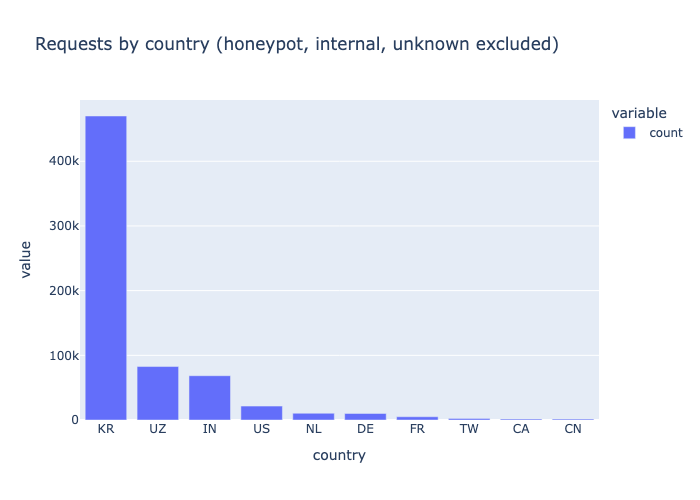

In [28]:
countries = real[~real.country.isin(['internal', 'unknown'])].country.value_counts().head(10)
px.bar(countries, title='Requests by country (honeypot, internal, unknown excluded)')

**Location findings**
- `country`/`city` come from Cloudflare: 748,772 of 748,790 JSON rows that came through Cloudflare have a country. Requests that skip Cloudflare (direct or Tailscale) mostly have none.
- Filled from our own data (same IP, same location). Internal IPs (147,595 rows) marked `internal`.
- Still unknown: 28,039 rows from 4,213 public IPs that never came through Cloudflare. Option: offline MaxMind GeoLite2 database (free account, IPs stay on this machine). Online geo APIs skipped: they would receive every user IP.
- Top countries (honeypot excluded): KR 469,997, UZ 82,653, IN 68,466, US 21,479.